In [59]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score

ModuleNotFoundError: No module named 'sklearn'

In [29]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("chaitanyajamble/grade-prediction-based-on-socioeconomic-factors")

print("Path to dataset files:", path)

Path to dataset files: /Users/freddiewhichello/.cache/kagglehub/datasets/chaitanyajamble/grade-prediction-based-on-socioeconomic-factors/versions/1


In [30]:
df = pd.read_csv(r'//student_grade_ses_dataset.csv')


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

In [42]:
for c in df.columns:
    if df[c].dtype == 'str':
        df[c] = df[c].fillna('na')

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      12025 non-null

In [32]:
df['residence_type'].unique()

<StringArray>
['Rural', 'Urban', 'Semi-Urban']
Length: 3, dtype: str

In [50]:
df.groupby(['family_income_bracket', 'residence_type','has_computer_or_laptop'])['has_internet_access'].agg(['median', 'mean'])

median      mean
family_income_bracket residence_type has_computer_or_laptop                  
High                  Rural          0                          1.0  0.563910
                                     1                          1.0  0.619565
                      Semi-Urban     0                          1.0  0.694915
                                     1                          1.0  0.766667
                      Urban          0                          1.0  0.827586
                                     1                          1.0  0.826855
Low                   Rural          0                          0.0  0.213528
                                     1                          0.0  0.165289
                      Semi-Urban     0                          0.0  0.384289
                                     1                          0.0  0.339080
                      Urban          0                          0.0  0.454414
                                     1                          0.0  0.478947
Lower-Middle          Rural          0                          0.0  0.314318
                                     1                          0.0  0.288820
                      Semi-Urban     0                          0.0  0.474771
                                     1                          0.0  0.473684
                      Urban          0                          1.0  0.550067
                                     1                          1.0  0.613419
Middle                Rural          0                          0.0  0.388250
                                     1                          0.0  0.424242
                      Semi-Urban     0                          1.0  0.572072
                                     1                          1.0  0.575668
                      Urban          0                          1.0  0.626340
                                     1                          1.0  0.628651
Upper-Middle          Rural          0                          0.0  0.491018
                                     1                          0.0  0.457875
                      Semi-Urban     0                          1.0  0.549383
                                     1                          1.0  0.609649
                      Urban          0                          1.0  0.679537
                                     1                          1.0  0.698077

In [ ]:
df.groupby(['residence_type'])['distance_to_school_km'].agg(['median', 'mean'])

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

In [18]:
df[pd.isna(df['annual_family_income_inr'])][['family_income_bracket','annual_family_income_inr']]

,family_income_bracket,annual_family_income_inr
41,Middle,NaN
81,Lower-Middle,NaN
87,Low,NaN
88,Lower-Middle,NaN
95,Upper-Middle,NaN
...,...,...
11956,Middle,NaN
11958,Low,NaN
11985,Middle,NaN
11998,Middle,NaN


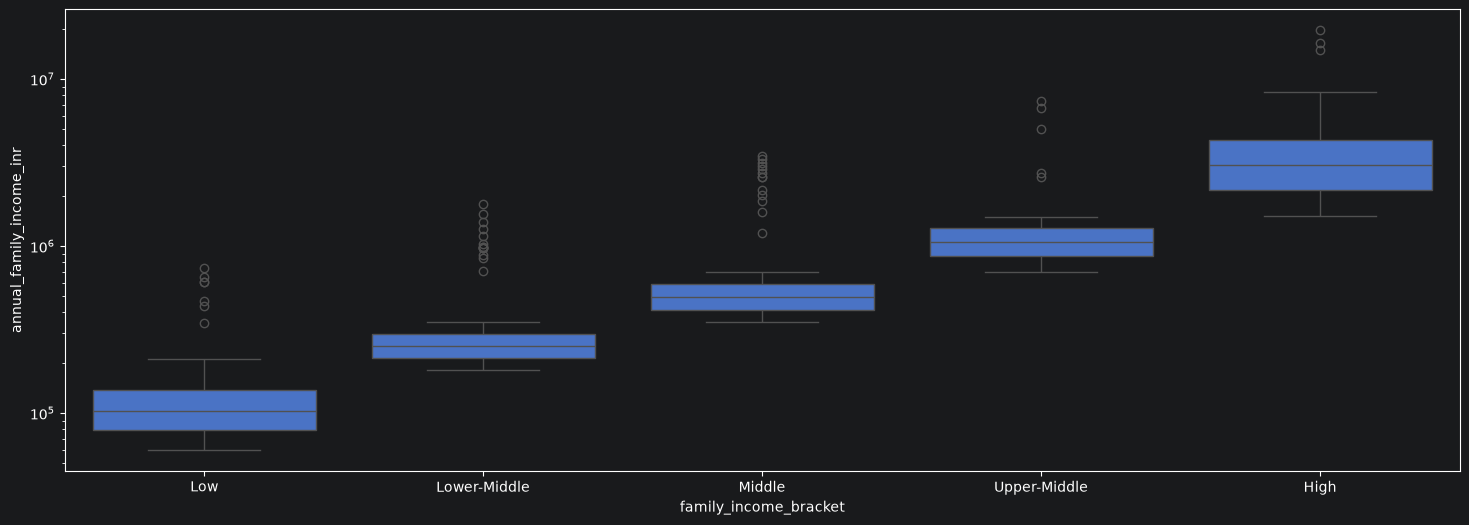

In [25]:
fig, ax= plt.subplots(figsize=(18, 6))
ax.set_yscale('log')
custom_order = ["Low", "Lower-Middle", "Middle",  "Upper-Middle", "High"]
sns.boxplot(x="family_income_bracket", y="annual_family_income_inr", data=df, ax=ax, order=custom_order)

plt.show()

In [27]:
df.groupby('family_income_bracket')['annual_family_income_inr'].agg(['median', 'mean'])

,median,mean
family_income_bracket,,
High,3056531.0,3.347583e+06
Low,103053.0,1.101716e+05
Lower-Middle,252931.0,2.599594e+05
Middle,495187.0,5.127856e+05
Upper-Middle,1051792.5,1.083854e+06


In [44]:
df['annual_family_income_inr'] = df['annual_family_income_inr'].fillna(
    df.groupby('family_income_bracket')['annual_family_income_inr'].transform('median')
)

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    12025 non-null  float64
 13  father_education_level      12025 non-null

In [47]:
df['distance_to_school_km'] = df['distance_to_school_km'].fillna(
    df.groupby('residence_type')['distance_to_school_km'].transform('median')
)

In [52]:
df['has_internet_access'] = df['has_internet_access'].fillna(
    df.groupby(['family_income_bracket', 'residence_type','has_computer_or_laptop'])['has_internet_access'].transform('mean')
)

In [55]:
df.groupby(['family_income_bracket', 'residence_type'])['attendance_rate_pct'].agg(['mean', 'median'])

mean  median
family_income_bracket residence_type                   
High                  Rural           87.880707   88.20
                      Semi-Urban      90.734831   91.45
                      Urban           91.385754   92.80
Low                   Rural           80.902294   80.75
                      Semi-Urban      84.395625   84.40
                      Urban           84.260586   84.20
Lower-Middle          Rural           82.521417   82.20
                      Semi-Urban      86.510629   86.90
                      Urban           86.396645   86.60
Middle                Rural           84.021372   84.00
                      Semi-Urban      88.039583   88.10
                      Urban           88.066419   88.20
Upper-Middle          Rural           85.714096   85.70
                      Semi-Urban      89.123377   89.60
                      Urban           89.004161   89.50

In [56]:
df['attendance_rate_pct'] = df['attendance_rate_pct'].fillna(
    df.groupby(['family_income_bracket', 'residence_type'])['attendance_rate_pct'].transform('median')
)